In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix



In [6]:
dirct = r"D:\1A_Studies\NTI\AI_For_Business\Data_Sets\Fashion_MNIST\fashion-mnist_train.csv"
df = pd.read_csv(dirct)

In [7]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:    ", X_test.shape)
print("Test labels:    ", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 23s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images:     (10000, 28, 28)
Test labels:     (10000,)


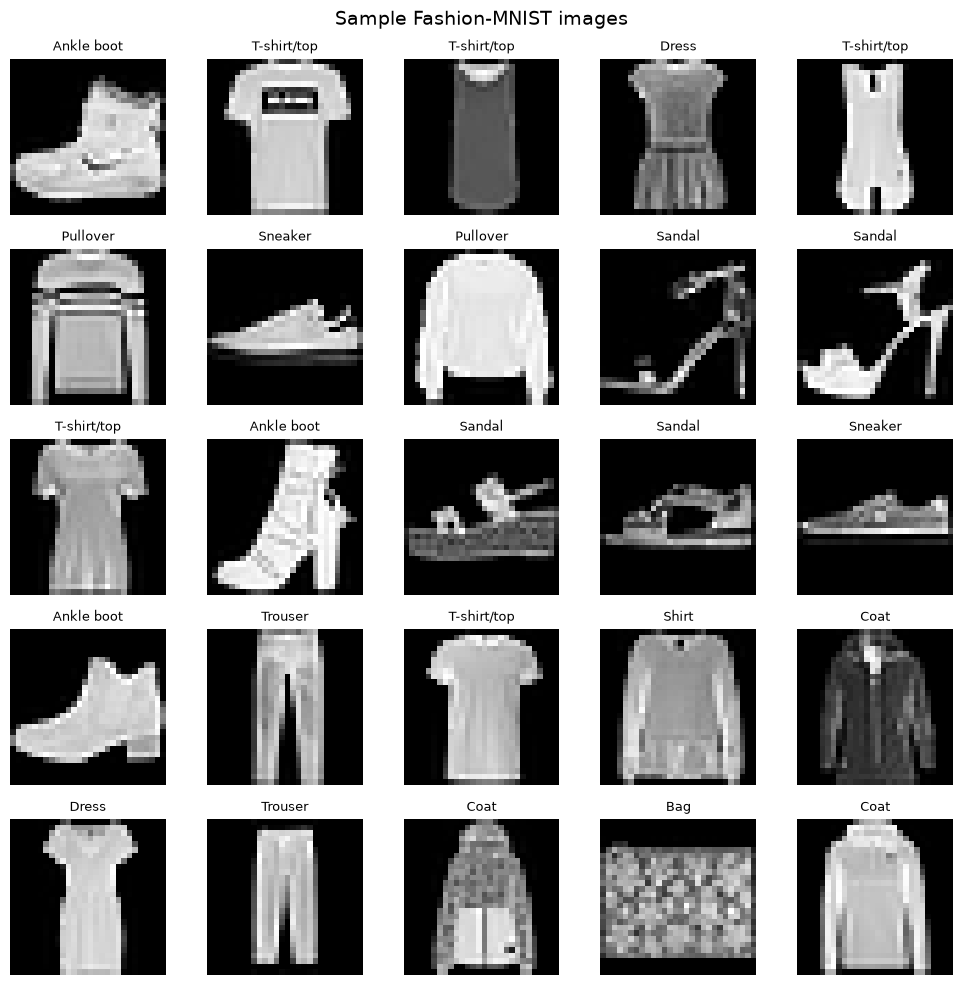

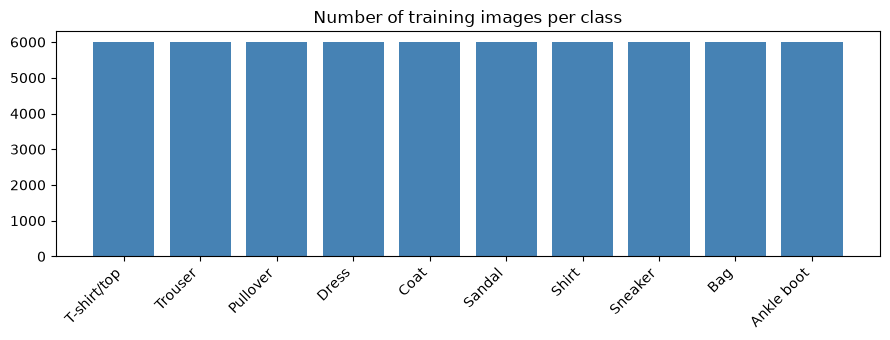

In [8]:
#@title 🔒 Code (hidden - click to show)
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]], fontsize=9)
    plt.axis("off")
plt.suptitle("Sample Fashion-MNIST images", fontsize=14)
plt.tight_layout()
plt.show()

unique, counts = np.unique(y_train_full, return_counts=True)
plt.figure(figsize=(9, 3.5))
plt.bar([class_names[i] for i in unique], counts, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.title("Number of training images per class")
plt.tight_layout()
plt.show()

In [9]:
#@title 🔒 Code (hidden - click to show)
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

X_valid, X_train = X_train_full[:5000], X_train_full[5000:]
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]

print("Train:     ", X_train.shape)
print("Validation:", X_valid.shape)
print("Test:      ", X_test.shape)
print("Pixel range after scaling:", X_train.min(), "to", X_train.max())

Train:      (55000, 28, 28)
Validation: (5000, 28, 28)
Test:       (10000, 28, 28)
Pixel range after scaling: 0.0 to 1.0


In [19]:
model = keras.Sequential([
    layers.Input(shape= (28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation= "relu"),
    layers.Dropout(0.3),
    layers.Dense(125, activation= "relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation= "softmax")
])
model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 125)            │        32,125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 125)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,345 (915.41 KB)

 Trainable params: 234,345 (915.41 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [22]:
#@title 🔒 Code (hidden - click to show)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_valid, y_valid),
    callbacks=[early_stopping],
    verbose=2,
)

print("\nTraining stopped after", len(history.history["loss"]), "epochs.")

Epoch 1/50
860/860 - 3s - 4ms/step - accuracy: 0.8605 - loss: 0.3862 - val_accuracy: 0.8760 - val_loss: 0.3327
Epoch 2/50
860/860 - 3s - 3ms/step - accuracy: 0.8654 - loss: 0.3660 - val_accuracy: 0.8820 - val_loss: 0.3271
Epoch 3/50
860/860 - 3s - 4ms/step - accuracy: 0.8721 - loss: 0.3479 - val_accuracy: 0.8826 - val_loss: 0.3176
Epoch 4/50
860/860 - 3s - 4ms/step - accuracy: 0.8750 - loss: 0.3398 - val_accuracy: 0.8860 - val_loss: 0.3105
Epoch 5/50
860/860 - 3s - 4ms/step - accuracy: 0.8787 - loss: 0.3266 - val_accuracy: 0.8814 - val_loss: 0.3263
Epoch 6/50
860/860 - 3s - 4ms/step - accuracy: 0.8825 - loss: 0.3201 - val_accuracy: 0.8832 - val_loss: 0.3183
Epoch 7/50
860/860 - 3s - 4ms/step - accuracy: 0.8857 - loss: 0.3093 - val_accuracy: 0.8858 - val_loss: 0.3082
Epoch 8/50
860/860 - 3s - 4ms/step - accuracy: 0.8858 - loss: 0.3041 - val_accuracy: 0.8878 - val_loss: 0.3059
Epoch 9/50
860/860 - 3s - 4ms/step - accuracy: 0.8897 - loss: 0.2965 - val_accuracy: 0.8892 - val_loss: 0.3094
E

In [23]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_valid, y_valid),
    verbose=2,
)

Epoch 1/20
860/860 - 3s - 4ms/step - accuracy: 0.8992 - loss: 0.2670 - val_accuracy: 0.8912 - val_loss: 0.2903
Epoch 2/20
860/860 - 3s - 4ms/step - accuracy: 0.8990 - loss: 0.2653 - val_accuracy: 0.8892 - val_loss: 0.2942
Epoch 3/20
860/860 - 3s - 4ms/step - accuracy: 0.9022 - loss: 0.2600 - val_accuracy: 0.9022 - val_loss: 0.2806
Epoch 4/20
860/860 - 3s - 3ms/step - accuracy: 0.9038 - loss: 0.2570 - val_accuracy: 0.8858 - val_loss: 0.3144
Epoch 5/20
860/860 - 3s - 3ms/step - accuracy: 0.9039 - loss: 0.2535 - val_accuracy: 0.9018 - val_loss: 0.2783
Epoch 6/20
860/860 - 3s - 3ms/step - accuracy: 0.9063 - loss: 0.2501 - val_accuracy: 0.9010 - val_loss: 0.2963
Epoch 7/20
860/860 - 3s - 3ms/step - accuracy: 0.9064 - loss: 0.2493 - val_accuracy: 0.9000 - val_loss: 0.2893
Epoch 8/20
860/860 - 3s - 3ms/step - accuracy: 0.9088 - loss: 0.2431 - val_accuracy: 0.9010 - val_loss: 0.2805
Epoch 9/20
860/860 - 3s - 3ms/step - accuracy: 0.9079 - loss: 0.2448 - val_accuracy: 0.9000 - val_loss: 0.2864
E

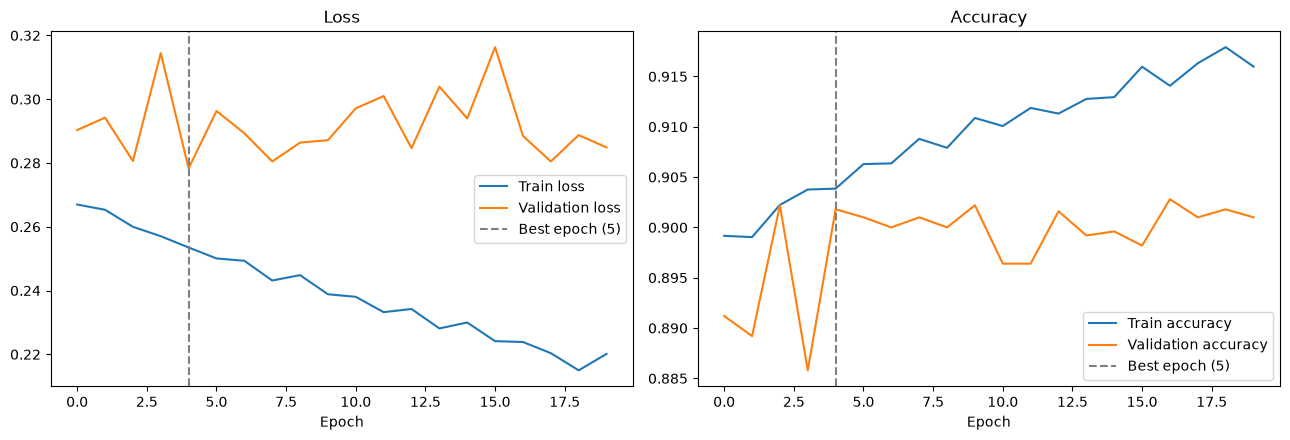

In [24]:
hist = history.history
best_epoch = int(np.argmin(hist["val_loss"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(hist["loss"], label="Train loss")
axes[0].plot(hist["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch + 1})")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(hist["accuracy"], label="Train accuracy")
axes[1].plot(hist["val_accuracy"], label="Validation accuracy")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch + 1})")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

In [26]:
import os

path = "main.ipynb"

print("Exists:", os.path.exists(path))
print("Size:", os.path.getsize(path), "bytes")

with open(path, "r", encoding="utf-8") as f:
    print(repr(f.read(200)))

Exists: True
Size: 0 bytes
''
